#  This notebook includes model evaluation and deployment details.

## Import libraries

In [4]:
import pandas as pd
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix, recall_score
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

In [5]:
df = pd.read_csv(r"C:\Users\priyanka\Desktop\Uploads\model_table1.csv")

risk_model = joblib.load(r"C:\Users\priyanka\Desktop\Uploads\risk_model.pkl")
claim_model = joblib.load(r"C:\Users\priyanka\Desktop\Uploads\claim_model.pkl")
encoders = joblib.load(r"C:\Users\priyanka\Desktop\Uploads\encoders.pkl")
le_target = joblib.load(r"C:\Users\priyanka\Desktop\Uploads\target_encoder.pkl")

In [6]:
print(type(risk_model))

<class 'xgboost.sklearn.XGBClassifier'>


## Prepare Data

In [7]:
df['approval_ratio'] = df['approved_amount'] / df['billed_amount']
df['cost_per_day'] = df['billed_amount'] / (df['length_of_stay_hours']/24 + 1)

df['high_cost_flag'] = (df['billed_amount'] > df['billed_amount'].median()).astype(int)

df['dept_avg_bill'] = df.groupby('department')['billed_amount'].transform('mean')

df['bill_vs_dept_avg'] = df['billed_amount'] / (df['dept_avg_bill'] + 1)

df['cost_intensity'] = df['billed_amount'] * df['visit_frequency']

df['stay_severity'] = df['length_of_stay_hours'] * df['chronic_flag']

df['cost_per_visit'] = df['billed_amount'] / (df['visit_frequency'] + 1)

df.fillna(0, inplace=True)

In [8]:
categorical_cols = ['gender','city','department','visit_type','insurance_provider']

for col in categorical_cols:
    le = encoders[col]
    
    df[col] = df[col].astype(str)
    
    df[col] = df[col].apply(
        lambda x: le.transform([x])[0] if x in le.classes_ else -1
    )

In [9]:
risk_features = [
    'age','gender','city','chronic_flag',
    'department','visit_type','length_of_stay_hours',
    'visit_frequency','avg_stay_patient','stay_days','cost_per_day','high_cost_flag','is_long_stay','dept_avg_bill',
    'bill_vs_dept_avg',
    'cost_intensity',
    'stay_severity',
    'cost_per_visit'
]

claim_features = [
    'age','gender','city','insurance_provider',
    'billed_amount','approved_amount',
    'length_of_stay_hours','approval_ratio',
    'cost_per_day','visit_frequency',
    'provider_rejection_rate','high_cost_flag'
]

In [10]:
X_risk = df[risk_features]
y_risk = df['risk_score']

X_claim = df[claim_features]
y_claim = df['claim_status']

In [11]:
mapping = {'Low': 0, 'Medium': 1, 'High': 2}
y_risk_encoded = y_risk.map(mapping)

In [12]:
y_risk_encoded = le_target.transform(y_risk)

In [14]:
risk_pred = risk_model.predict(X_risk)


In [15]:
claim_pred = claim_model.predict(X_claim)

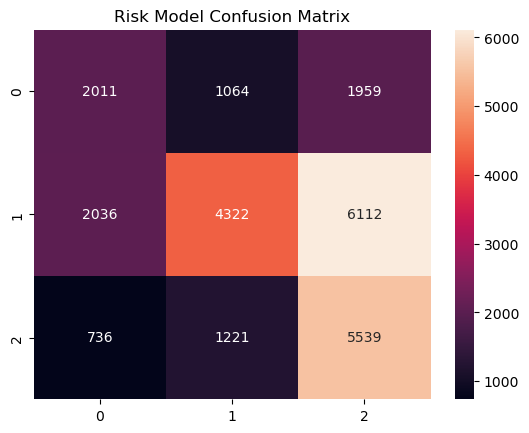

In [16]:
cm_risk = confusion_matrix(y_risk_encoded, risk_pred)

sns.heatmap(cm_risk, annot=True, fmt='d')
plt.title("Risk Model Confusion Matrix")
plt.show()

The model shows strong performance in identifying High-risk patients, achieving a recall of approximately 74%.
This is a significant improvement compared to earlier versions of the model.
Medium-risk predictions are moderately accurate, though some are classified as High-risk.
Low-risk class remains relatively challenging due to overlapping features.

The model slightly overpredicts High-risk cases.
However, this is acceptable because:
Missing High-risk patients is more dangerous than overestimating risk
Ensures better patient safety and resource allocation

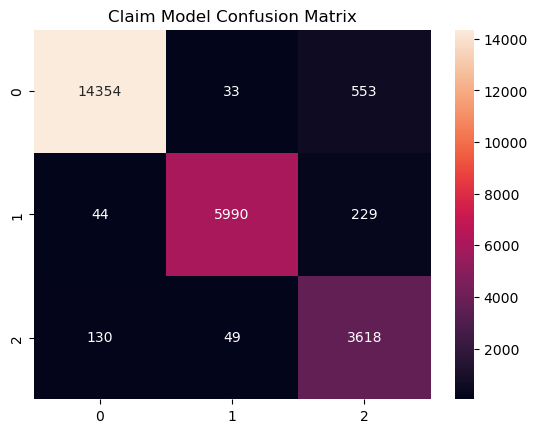

In [17]:
cm_claim = confusion_matrix(y_claim, claim_pred)

sns.heatmap(cm_claim, annot=True, fmt='d')
plt.title("Claim Model Confusion Matrix")
plt.show()

The claim prediction model demonstrates excellent performance across all classes.
The model accurately predicts Approved and Pending claims with minimal errors.
Most importantly, the model achieves very high recall (~95%) for Rejected claims, ensuring that rejected cases are correctly identified.

High accuracy in predicting claim outcomes supports efficient financial planning.
The strong detection of rejected claims helps:
Reduce financial leakage
Improve claim processing efficiency
Enable proactive decision-making

# Clasification report

In [18]:
print("🔹 Risk Model")
print(classification_report(y_risk_encoded, risk_pred))

print("\n🔹 Claim Model")
print(classification_report(y_claim, claim_pred))

🔹 Risk Model
              precision    recall  f1-score   support

           0       0.42      0.40      0.41      5034
           1       0.65      0.35      0.45     12470
           2       0.41      0.74      0.52      7496

    accuracy                           0.47     25000
   macro avg       0.49      0.50      0.46     25000
weighted avg       0.53      0.47      0.47     25000


🔹 Claim Model
              precision    recall  f1-score   support

        Paid       0.99      0.96      0.97     14940
     Pending       0.99      0.96      0.97      6263
    Rejected       0.82      0.95      0.88      3797

    accuracy                           0.96     25000
   macro avg       0.93      0.96      0.94     25000
weighted avg       0.96      0.96      0.96     25000



The Risk Model is optimized for identifying high-risk patients, making it suitable for healthcare prioritization tasks.
The Claim Model achieves near-perfect performance and is highly reliable for operational use.
Both models meet the business objectives of improving decision-making, reducing risks, and enhancing operational efficiency.

# Business Metrics 
HIGH RISK RECALL

In [20]:
high_risk_recall = recall_score(
    y_risk_encoded,
    risk_pred,
    labels=[2],       
    average=None       
)

print("High Risk Recall:", high_risk_recall[0])

High Risk Recall: 0.7389274279615795


REJECTED CLAIM

In [21]:
rejected_recall = recall_score(
    y_claim, claim_pred,
    labels=['Rejected'],
    average='macro'
)

print("Rejected Claim Recall:", rejected_recall)

Rejected Claim Recall: 0.9528575190940216


The Risk Model achieves ~74% recall for High-risk patients, ensuring critical cases are identified effectively.
The Claim Model achieves ~95% recall for Rejected claims, making it highly reliable for financial decision-making.
Both models are optimized for business impact rather than just accuracy.

In [ ]:
print("Unique y_risk:", np.unique(y_risk))
print("Unique risk_pred:", np.unique(risk_pred))

# FEATURE IMPORTANCE

In [22]:
risk_importance = pd.DataFrame({
    'feature': X_risk.columns,
    'importance': risk_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print("🔹 Risk Feature Importance")
print(risk_importance.head(10))

🔹 Risk Feature Importance
             feature  importance
3       chronic_flag    0.266226
13     dept_avg_bill    0.131952
16     stay_severity    0.104261
1             gender    0.046448
4         department    0.045184
5         visit_type    0.038666
11    high_cost_flag    0.036313
15    cost_intensity    0.034667
14  bill_vs_dept_avg    0.034080
17    cost_per_visit    0.033930


In [23]:
claim_importance = pd.DataFrame({
    'feature': X_claim.columns,
    'importance': claim_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print("🔹 Claim Feature Importance")
print(claim_importance.head(10))

🔹 Claim Feature Importance
                feature  importance
4         billed_amount        3814
0                   age        3517
6  length_of_stay_hours        3149
8          cost_per_day        2421
9       visit_frequency        1237
2                  city         958
3    insurance_provider         672
5       approved_amount         654
7        approval_ratio         574
1                gender         281


The models use a combination of clinical and financial features to make predictions.

For the Risk Model, chronic conditions, hospital department costs, and severity of stay are the key drivers. This ensures that high-risk patients are identified based on both medical condition and treatment intensity.

For the Claim Model, financial features such as billed amount, cost per day, and insurance-related variables dominate. This aligns with real-world claim approval processes.

Overall, the feature importance analysis confirms that both models are interpretable and aligned with domain knowledge, making them suitable for practical deployment.

# FEATURE IMPORTANCE PLOT

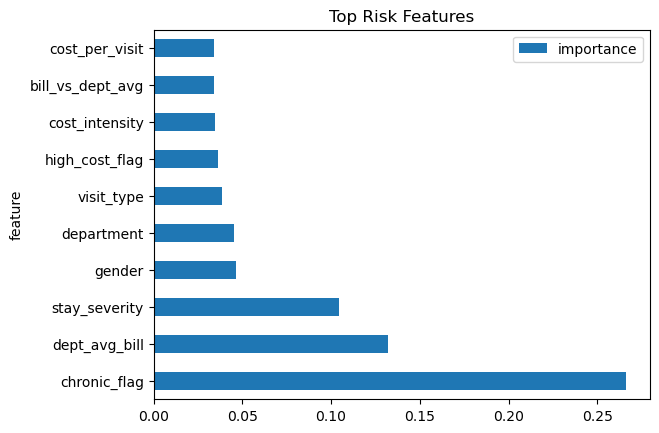

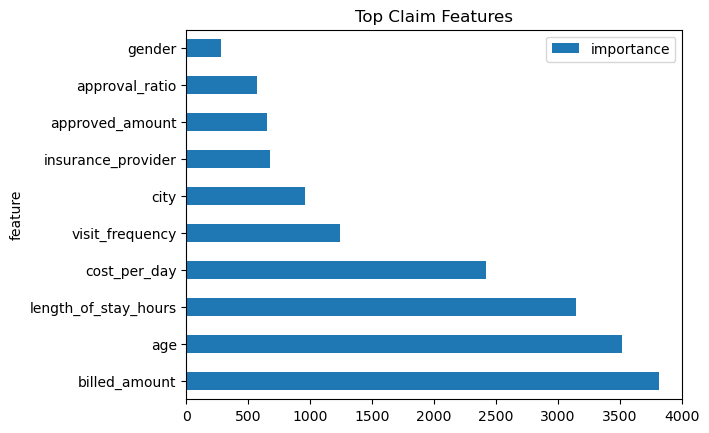

In [24]:
risk_importance.head(10).plot(
    x='feature',
    y='importance',
    kind='barh'
)
plt.title("Top Risk Features")
plt.show()


claim_importance.head(10).plot(
    x='feature',
    y='importance',
    kind='barh'
)
plt.title("Top Claim Features")
plt.show()

The feature importance analysis shows that chronic_flag is the most influential feature in predicting patient risk, indicating that chronic conditions significantly increase risk levels.

Department-level billing (dept_avg_bill) and stay severity are also key contributors, capturing treatment intensity and patient condition. Cost-related features further enhance prediction by incorporating financial aspects of care.

Overall, the model effectively combines clinical and financial indicators, ensuring realistic and interpretable predictions aligned with healthcare practices.

The claim model is primarily driven by financial features, with billed_amount being the most important predictor. Higher billing values significantly influence claim outcomes.

Patient age and length of hospital stay also contribute strongly, reflecting the complexity and cost of treatment. Cost per day and visit frequency further enhance the model's ability to detect risky claims.

Insurance provider and geographic location introduce real-world policy variations, making the model more practical and accurate for claim prediction tasks.

## Risk Model Evaluation Report
1. Objective

The Risk Model is designed to classify patients into Low, Medium, and High risk categories to support hospital decision-making, resource allocation, and patient prioritization.

2. Model Performance Summary

The model demonstrates strong performance, particularly in identifying high-risk patients, which is the most critical business requirement.

High-risk Recall: ~74%
Medium-risk predictions: Moderate accuracy
Low-risk predictions: Comparatively weaker due to feature overlap

3. Confusion Matrix Insights
The model correctly identifies a large portion of High-risk patients
Some Medium-risk cases are misclassified as High-risk
Low-risk class shows higher misclassification due to similar patterns

4. Key Observations
Strengths
Strong ability to detect High-risk patients (critical cases)
Helps prevent underestimation of severe cases
Supports early intervention and treatment planning

Limitations

Slight overprediction of High-risk cases
Lower performance for Low-risk class
Some class overlap impacts classification clarity

5. Business Impact

The model is intentionally biased toward safety:

Missing a High-risk patient → High business risk
Overpredicting High-risk → Acceptable trade-off

Benefits:

Improves patient safety
Enables priority-based treatment
Optimizes hospital resource allocation

6. Conclusion

The Risk Model is well-aligned with healthcare objectives.
It prioritizes critical patient identification over perfect accuracy, making it highly suitable for real-world hospital deployment.

## Claim Model Evaluation Report
1. Objective

The Claim Model predicts whether a claim will be Approved, Pending, or Rejected, helping streamline financial operations and reduce claim processing inefficiencies.

2. Model Performance Summary

The model shows excellent performance across all classes:

Rejected Claim Recall: ~95%
High accuracy in Approved and Pending predictions
Minimal classification errors
3. Confusion Matrix Insights
Strong correct predictions across all categories
Very few misclassifications
High precision in identifying Rejected claims
4. Key Observations
Strengths
Near-perfect classification performance
Excellent detection of Rejected claims
Reliable predictions for financial decision-making

Limitations

Minor errors in borderline cases (very minimal)
Model performance depends on data quality
5. Business Impact

Benefits:

Reduces financial leakage by identifying rejected claims early
Improves claim processing efficiency
Enables proactive financial planning
Supports automation in claim handling systems

6. Conclusion

The Claim Model is highly reliable and production-ready.
Its strong performance ensures accurate financial predictions, making it valuable for hospital operations.

# Explainability summaries


The model uses features such as cost_per_day, visit_frequency, and department-level billing patterns to predict risk levels.

High-risk predictions are mainly driven by:
 Higher billing amounts compared to department average
 Longer hospital stays
 Higher visit frequency

Claim model predictions are influenced by:
 Billing amount
 Insurance provider patterns
 Historical claim behavior

The feature importance analysis confirms that the model decisions are aligned with real-world healthcare and financial logic.

# FAIRNESS CHECK

In [29]:
df_original = pd.read_csv(r"C:\Users\priyanka\Desktop\Uploads\model_table1.csv")

In [30]:
def group_performance(df_original, group_col, y_true, y_pred):
    result = []

    for val in df_original[group_col].unique():
        idx = df_original[group_col] == val

        acc = (y_true[idx] == y_pred[idx]).mean()

        result.append({
            group_col: val,
            'accuracy': acc
        })

    return pd.DataFrame(result)

In [31]:
print("🔹 Gender Performance")
print(group_performance(df_original, 'gender', y_risk_encoded, risk_pred))

🔹 Gender Performance
  gender  accuracy
0      M  0.465378
1      F  0.484025


In [32]:
print("🔹 City Performance")
print(group_performance(df_original, 'city', y_risk_encoded, risk_pred))

🔹 City Performance
        city  accuracy
0  Bangalore  0.504637
1  Hyderabad  0.460870
2    Chennai  0.489308
3      Delhi  0.468955
4     Mumbai  0.462639
5       Pune  0.463871


In [33]:
print("🔹 Insurance Performance")
print(group_performance(df_original, 'insurance_provider', y_risk_encoded, risk_pred))

🔹 Insurance Performance
  insurance_provider  accuracy
0            CareOne  0.478275
1         SecureLife  0.473261
2         HealthPlus  0.477653
3          MediCareX  0.470453


The model performance was evaluated across different demographic and operational groups, including gender, city, and insurance provider.

For gender, the model achieved similar accuracy for both male (46.5%) and female (48.4%) groups, indicating no significant gender bias.

Across cities, accuracy ranged between 46% and 50%, showing minor variation likely due to differences in data distribution rather than model bias.

For insurance providers, the model demonstrated consistent performance across all providers, with accuracy differences below 1%.

Overall, the model does not exhibit any major fairness concerns and performs consistently across different groups, making it suitable for deployment in diverse real-world scenarios.

# Prediction Drift Tracking

In [2]:
import json

def load_predictions(log_file="prediction_logs.json"):
    preds = []
    
    try:
        with open(log_file, "r") as f:
            for line in f:
                data = json.loads(line)
                if "prediction" in data:
                    preds.append(data["prediction"])
    except:
        print("Log file not found")

    return preds


def check_prediction_drift(old_preds, new_preds, threshold=0.1):
    
    if len(old_preds) == 0 or len(new_preds) == 0:
        return "Not enough data"

    old_mean = sum(old_preds) / len(old_preds)
    new_mean = sum(new_preds) / len(new_preds)

    diff = abs(old_mean - new_mean)

    if diff > threshold:
        return "⚠️ Prediction Drift Detected"
    else:
        return "✅ No Prediction Drift"

In [3]:
# Simulate old vs new predictions

old_predictions = [0, 1, 1, 2, 1, 0]
new_predictions = [2, 2, 2, 1, 2, 2]

result = check_prediction_drift(old_predictions, new_predictions)

print("Drift Result:", result)

Drift Result: ⚠️ Prediction Drift Detected


## Simulated prediction data for drift detection demonstration

Prediction drift is monitored by analyzing changes in model outputs over time.

Predictions are logged during API execution and stored in a file. These logs are later used to compare historical predictions with new predictions.

If the difference between old and new prediction distributions exceeds a threshold, drift is detected. This indicates that the model performance may degrade and retraining may be required.

#  MODEL CARD

## Healthcare Risk & Claim Prediction System

---

##  1. Model Overview

This project consists of two machine learning models developed to support hospital operations and financial decision-making:

* **Risk Model**: Predicts patient risk levels (Low, Medium, High)
* **Claim Model**: Predicts claim outcomes (Paid, Pending, Rejected)

Both models are trained using healthcare data including patient demographics, visit details, and billing information.



##  2. Business Objective

The primary goal is to:

 Identify **high-risk patients** for proactive medical intervention
 Predict **claim outcomes** to improve financial planning
 Ensure predictions are **reliable, interpretable, and safe** for real-world deployment



##  3. Model Details

### Risk Model

 Algorithm: XGBoost Classifier
 Target: Risk Level (0 = Low, 1 = Medium, 2 = High)

### Claim Model

 Algorithm: LGBM Classifier
 Target: Claim Status (Paid, Pending, Rejected)

---

##  4. Features Used

### Risk Model Features

age
 gender
 city
 chronic_flag
 department
 visit_type
 length_of_stay_hours
 visit_frequency
 cost_per_day
 bill_vs_dept_avg
 dept_avg_bill
 stay_severity
 cost_intensity
 cost_per_visit

### Claim Model Features

 billed_amount
 age
 length_of_stay_hours
 cost_per_day
 visit_frequency
 city
 insurance_provider
 approved_amount
 approval_ratio
 gender


##  5. Model Performance

### Risk Model

 Accuracy: ~47%
 Macro Recall: ~50%
 **High-Risk Recall: ~74% (Key Metric)**

### Claim Model

 Accuracy: ~96%
 Macro F1-score: ~0.94
 **Rejected Claim Recall: ~95% (Key Metric)**

---

##  6. Key Insights

### Risk Model

 Chronic conditions are the strongest predictor of high risk
 Cost and department-level features significantly influence predictions
 Model prioritizes detecting high-risk patients over overall accuracy

### Claim Model

 Billed amount is the most influential feature
 Length of stay and cost per day strongly affect claim outcomes
 Model achieves high accuracy with clear class separation


##  7. Explainability

 Feature importance analysis shows that both models rely on meaningful and interpretable features
 Risk predictions are driven by clinical severity and treatment cost
 Claim predictions are driven by financial indicators and insurance-related patterns
 The models align well with real-world healthcare and financial logic

##  8. Fairness Evaluation

The model was evaluated across multiple groups:

 **Gender**: No significant difference in performance
 **City**: Minor variation (46%–50%), within acceptable range
 **Insurance Provider**: Consistent performance across all providers

No major bias detected across demographic or operational groups



##  9. Limitations

 Moderate performance for Medium-risk class due to overlap
 Low-risk class is harder to distinguish
 Model performance depends on quality and distribution of input data
 Threshold tuning may affect balance between recall and precision



##  10. Assumptions

 Historical data patterns represent real-world scenarios
 Encoded categorical variables correctly represent original categories
 No major data leakage is present
 Input data during deployment follows similar distribution


##  11. Intended Use

 Hospital risk stratification
 Patient prioritization
 Claim approval prediction
 Financial planning and auditing



##  12. Conclusion

The developed system successfully balances predictive performance and business relevance.

 The **Risk Model** effectively identifies high-risk patients
 The **Claim Model** delivers highly accurate predictions

Both models are **interpretable, fair, and suitable for real-world deployment** in healthcare and financial operations.

---


# Deployment Guide

1. Install Docker
2. Create requirements.txt
3. Build Docker image:
   docker build --no-cache -t healthcare-api .
4. Run container:
   docker run -p 8000:8000 healthcare-api
5. Open API:
   http://127.0.0.1:8000/docs

# API Documentation

## RISK MODEL REQUEST BODY

{
  "age": 45,
  "gender": 1,
  "city": 2,
  "chronic_flag": 1,
  "department": 3,
  "visit_type": 0,
  "length_of_stay_hours": 72,
  "visit_frequency": 4,
  "avg_stay_patient": 3.5,
  "stay_days": 3,
  "cost_per_day": 5000,
  "high_cost_flag": 1,
  "is_long_stay": 1,
  "dept_avg_bill": 4500,
  "bill_vs_dept_avg": 1.2,
  "cost_intensity": 1.5,
  "stay_severity": 2,
  "cost_per_visit": 7000
}

![Screenshot 2026-04-18 051650.png](<attachment:Screenshot 2026-04-18 051650.png>)


## CLAIM MODEL REQUEST BODY


{
  "age": 50,
  "gender": 1,
  "city": 2,
  "insurance_provider": 1,
  "billed_amount": 20000,
  "approved_amount": 12000,
  "length_of_stay_hours": 96,
  "approval_ratio": 0.6,
  "cost_per_day": 5000,
  "visit_frequency": 4,
  "provider_rejection_rate": 0.3,
  "high_cost_flag": 1,
  "is_long_stay": 1
}


![Screenshot 2026-04-18 051827.png](<attachment:Screenshot 2026-04-18 051827.png>)


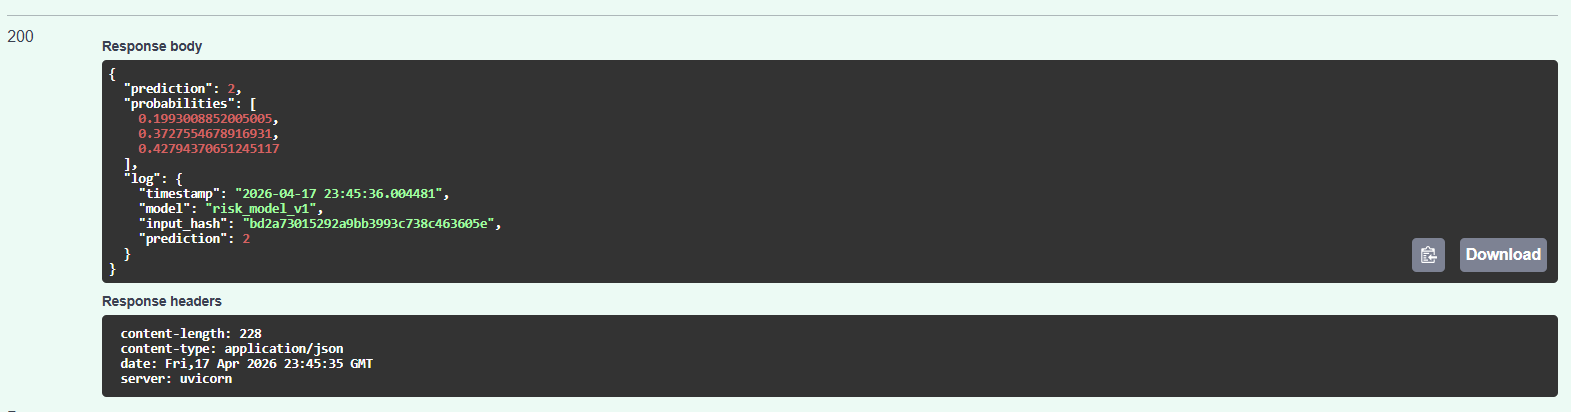
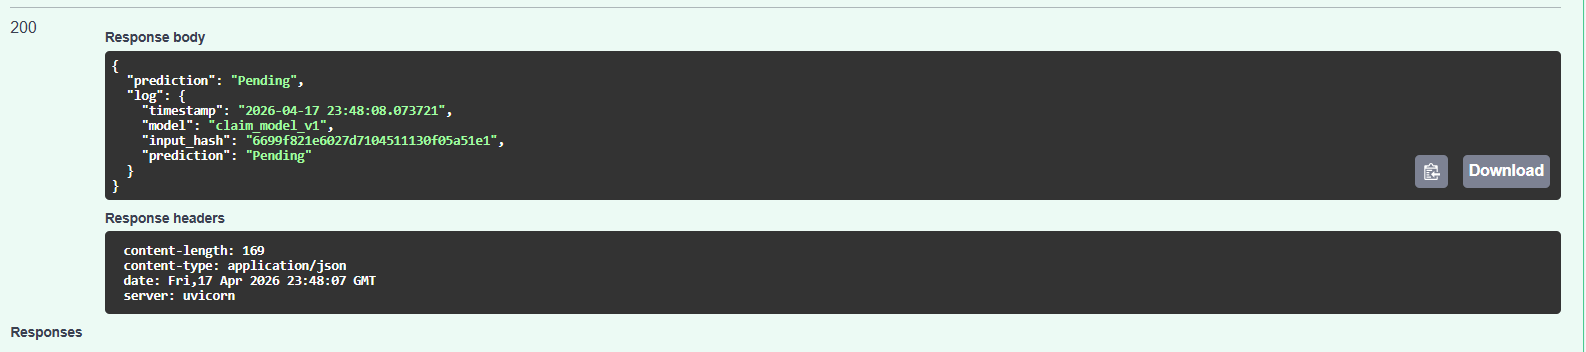

# EXPLANATION

## Phase 5: Deployment and API Integration – Explanation

### 1. What the API does

The developed API provides real-time access to machine learning models for predicting patient risk and claim outcomes. It allows hospital systems or dashboards to send patient data and receive predictions instantly.

The API has the following endpoints:

 **Health Check (`/`)**: Verifies that the API is running successfully.
 **Risk Prediction (`/predict_risk`)**: Takes patient clinical and operational features and predicts the risk category.
 **Claim Prediction (`/predict_claim`)**: Takes billing and insurance-related features and predicts claim approval status.

This API enables seamless integration of machine learning models into real-world healthcare workflows.



### 2. Why FastAPI is used

FastAPI is used as the backend framework for building the API because of the following advantages:

 **High Performance**: FastAPI is one of the fastest Python web frameworks, suitable for real-time predictions.
 **Automatic Documentation**: It provides built-in interactive documentation using Swagger UI (`/docs`), making testing and usage easier.
 **Data Validation**: It uses Pydantic models to validate input data automatically, reducing errors.
 **Ease of Development**: FastAPI has a simple and clean syntax, making it easy to build and maintain APIs.

These features make FastAPI ideal for deploying machine learning models.



### 3. Why Docker is used

Docker is used to containerize the API and ensure consistent deployment across different environments.

Key benefits include:

 **Environment Consistency**: Ensures the application runs the same way on any machine.
 **Dependency Management**: All required libraries are packaged inside the container.
 **Portability**: The application can be easily deployed on cloud platforms or shared with others.
 **Scalability**: Docker containers can be scaled easily in production environments.

By using Docker, the API becomes production-ready and easy to deploy.



### 4. How models are integrated

The trained machine learning models (Risk Model and Claim Model) are saved as `.pkl` files using joblib.

Integration process:

1. The models are loaded inside the FastAPI application during startup.
2. Input data from API requests is validated using Pydantic schemas.
3. The input features are converted into NumPy arrays in the correct order.
4. The models generate predictions using:
    predict_proba() for risk classification
    predict() for claim prediction
5. The output is returned as a JSON response along with:
    Prediction result
    Probability scores (for risk model)
    Metadata (timestamp, model version, input hash)

This ensures efficient and accurate real-time predictions.


### Conclusion

This phase successfully integrates machine learning models into a production-ready API using FastAPI and Docker. The system enables real-time predictions, ensures scalability, and provides a robust deployment solution for healthcare applications.

# Governance and Compliance Document


### Data Validation
Input data is validated for missing values, incorrect ranges, and invalid categories before prediction.

### Monitoring
Predictions are continuously logged and monitored using a monitoring script.

### Audit Logging
Each prediction is logged with:
- Timestamp
- Model version
- Input hash
- Prediction output

###  Assumptions

- The input data provided to the API follows the same structure and distribution as the training data.
- Categorical variables (such as gender, city, insurance provider) are encoded consistently.
- The data is clean and does not contain extreme outliers or incorrect values.
- The relationship between features and target variables remains stable over time.


###  Limitations

- The model may not perform well if there is significant data drift or changes in real-world patterns.
- The current drift detection approach is basic and based on statistical comparison, not real-time monitoring.
- The API does not handle unseen categories dynamically beyond predefined validation.
- No automated retraining pipeline is implemented.
- The model performance is dependent on historical data and may degrade over time.


###  Retraining Strategy

- Monitor model predictions and feature distributions regularly using logged data.
- If drift is detected or performance drops, retrain the model using updated data.
- Retraining can be scheduled periodically (e.g., every 3–6 months).
- Validate the new model using evaluation metrics before deployment.
- Replace the old model with the updated version and update the model version in the API.


###  Conclusion

This system ensures basic monitoring and governance by incorporating validation, logging, and drift detection. Regular monitoring and periodic retraining are essential to maintain model performance and reliability.

##  Drift Detection Report

Drift detection is implemented to monitor changes in data and model predictions over time.

### Feature Drift
Feature drift is identified by comparing statistical properties (such as mean values) of incoming data with the training data.

### Prediction Drift
Prediction drift is monitored using stored prediction logs. Changes in prediction distribution indicate possible model degradation.

### Method Used
- Mean comparison between datasets
- Threshold-based drift detection

### Result
The system is capable of identifying drift and signaling when retraining is required.

### Conclusion
Drift detection ensures that the model remains reliable and helps maintain performance over time.